# Hardy Cross method: balancing a pipe network with Python
### A guided case study for first-year engineering students

*Python for Engineers: Case Studies from Calculator to Simulation* · Notebook 16 · Yanwei Wang

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/python-for-engineers-case-studies/blob/main/notebooks/16_Hardy_Cross_Pipe_Networks.ipynb)

**Question.** A water network has known inflow, customer withdrawals, and pipe resistances. How much water flows through each pipe? Junction balance tells us how much must enter and leave each node, but it does not by itself determine the division among parallel routes. The **Hardy Cross method** adjusts flows around closed loops until their signed head changes add to zero.

This notebook begins with one feasible flow guess, derives the correction, implements the original sequential loop idea, checks the result by independent head calculations, and explores another starting guess and a changed pipe resistance. An optional two-variable matrix solve connects the example to linear algebra. The example data are **constructed for teaching** and are not a design for a real water system.

**Run order and tools.** Run cells from top to bottom in Jupyter Notebook or JupyterLab. Only Python, NumPy, and Matplotlib are needed (`python -m pip install numpy matplotlib` if needed). No data file or SciPy is required. Read the code comments as part of the lesson: each executable line has a comment explaining its purpose or reasoning. Predict the sign of a correction before running its cell. The optional section may be skipped on a first reading.

**What you should learn.** Represent a network using lists, dictionaries, and arrays; distinguish continuity at junctions from energy balance around loops; use signed flows and units consistently; trace a bounded iterative algorithm; visualize convergence; and test a calculation with independent checks. This is a self-study example.

<!-- pfe-study-guide -->
## Study guide

| | |
|---|---|
| **Status** | Core · Part 6, Engineering practice |
| **Time** | about 35 min (about 70 min with exercises) |
| **Before this** | Notebooks 02 and 05; flow and head loss at an introductory level. |
| **Essential** | Sections 1–10 and 12. |
| **Optional on a first reading** | Section 11 (the coupled Newton check). |
| **Next** | 17, Linear algebra for engineers. |

**You have understood this notebook if you can, without looking back:**

1. Check flow conservation at every junction for a given guess.
2. Explain the signed head-loss law h = rQ|Q| and the sign convention around a loop.
3. Compute one loop correction Δ and say why it has the sign it has.
4. Iterate until both loop residuals are below the tolerance, then verify both laws on the result.
5. Explain why loop corrections cannot repair a starting guess that breaks flow conservation.

**Not expected of you:** Deriving the correction formula: following it once is enough.

*The comment on every code line is a reading aid. In your own programs, comment the reasons and the non-obvious steps.*

## Reading map and assumptions

| Step | Programming idea | Engineering idea |
|:--|:--|:--|
| Define pipes and junctions | Lists of tuples, dictionaries, array order | Reference direction and external demand |
| Check an initial flow guess | Nested loops, indexing, assertions | Conservation at every junction |
| Calculate head changes | Functions, signed values, units | Nonlinear resistance law |
| Correct loops | `for`, `if`, copies, tolerances | Head balance and shared pipes |
| Check and plot answers | Arrays, figures, independent calculations | Residuals, sensitivity, limitations |

**Model assumptions.** Steady, incompressible flow; specified external injections and withdrawals; no leaks, pumps, valves, or tanks inside the seven pipes; and a fixed positive resistance coefficient for each pipe. Junctions have a single total hydraulic head. For this teaching exercise use

$$h_i(Q_i)=r_iQ_i|Q_i|,$$

where $Q_i$ is **signed** in L/s, $r_i$ has units m/(L/s)$^2$, and $h_i$ is a **signed** head change in metres from a pipe's named tail to its named head. A positive $Q_i$ gives a positive drop in the named direction; a negative $Q_i$ gives a negative drop, meaning physical flow goes the other way. The magnitude is $r_iQ_i^2$. A fixed quadratic law is an approximation: a real Darcy–Weisbach friction factor can change with Reynolds number, and pumps or pressure-dependent demands require a richer model.

In [1]:
# Import NumPy for compact arrays and matrix checks of the network balances.
import numpy as np
# Import pyplot to draw the topology, changes in flows, and iteration history.
import matplotlib.pyplot as plt
# Use a readable default figure size in the notebook output.
plt.rcParams['figure.figsize'] = (8, 4.5)
# State the pipe order once; every array below uses this exact order.
pipe_names = ['AB', 'BC', 'DE', 'EF', 'AD', 'BE', 'CF']
# Give each pipe a tail and head that define its positive reference direction.
pipe_ends = [('A', 'B'), ('B', 'C'), ('D', 'E'), ('E', 'F'), ('A', 'D'), ('B', 'E'), ('C', 'F')]
# Store the junction order for the continuity vector and head calculations.
node_names = ['A', 'B', 'C', 'D', 'E', 'F']
# Assign horizontal and vertical coordinates only for the network drawing.
node_positions = {'A': (0, 1), 'B': (1, 1), 'C': (2, 1), 'D': (0, 0), 'E': (1, 0), 'F': (2, 0)}
# Specify positive pipe resistance values in m/(L/s)^2.
resistances = np.array([0.0010, 0.0015, 0.0020, 0.0012, 0.0018, 0.0010, 0.0025])
# Let A supply 100 L/s while C, D, E, and F withdraw 25, 20, 20, and 35 L/s.
external_flow = np.array([100.0, 0.0, -25.0, -20.0, -20.0, -35.0])
# Give the seven pipes a deliberately imperfect but junction-balanced starting flow in L/s.
initial_flow = np.array([70.0, 30.0, 10.0, 30.0, 30.0, 40.0, 5.0])
# Show that the external supply exactly matches the total withdrawals.
assert np.isclose(external_flow.sum(), 0.0)
# Verify that there is one resistance and one direction for every named pipe.
assert len(pipe_names) == len(pipe_ends) == len(resistances) == len(initial_flow)
# Print a compact legend so the data can be read before the first figure.
for name, ends, resistance, flow in zip(pipe_names, pipe_ends, resistances, initial_flow):
    # State pipe direction, resistance, and initial signed flow with their units.
    print(f'{name}: {ends[0]}->{ends[1]}, r={resistance:.4f} m/(L/s)^2, Q0={flow:5.1f} L/s')

AB: A->B, r=0.0010 m/(L/s)^2, Q0= 70.0 L/s
BC: B->C, r=0.0015 m/(L/s)^2, Q0= 30.0 L/s
DE: D->E, r=0.0020 m/(L/s)^2, Q0= 10.0 L/s
EF: E->F, r=0.0012 m/(L/s)^2, Q0= 30.0 L/s
AD: A->D, r=0.0018 m/(L/s)^2, Q0= 30.0 L/s
BE: B->E, r=0.0010 m/(L/s)^2, Q0= 40.0 L/s
CF: C->F, r=0.0025 m/(L/s)^2, Q0=  5.0 L/s


## 1. See the network before computing

The diagram shows two adjacent squares. **Left loop:** A → B → E → D → A. **Right loop:** B → C → F → E → B. Both loops pass through pipe **BE**, but in opposite traversal directions. Arrows on pipes define **reference directions**, not an assumption that the solved physical flow must always point that way. A negative answer simply reverses its arrow.

The coordinates below are for the drawing only. They are not lengths, elevations, or hydraulic inputs. In particular, these labels do **not** supply pipe diameters or actual geographic locations.

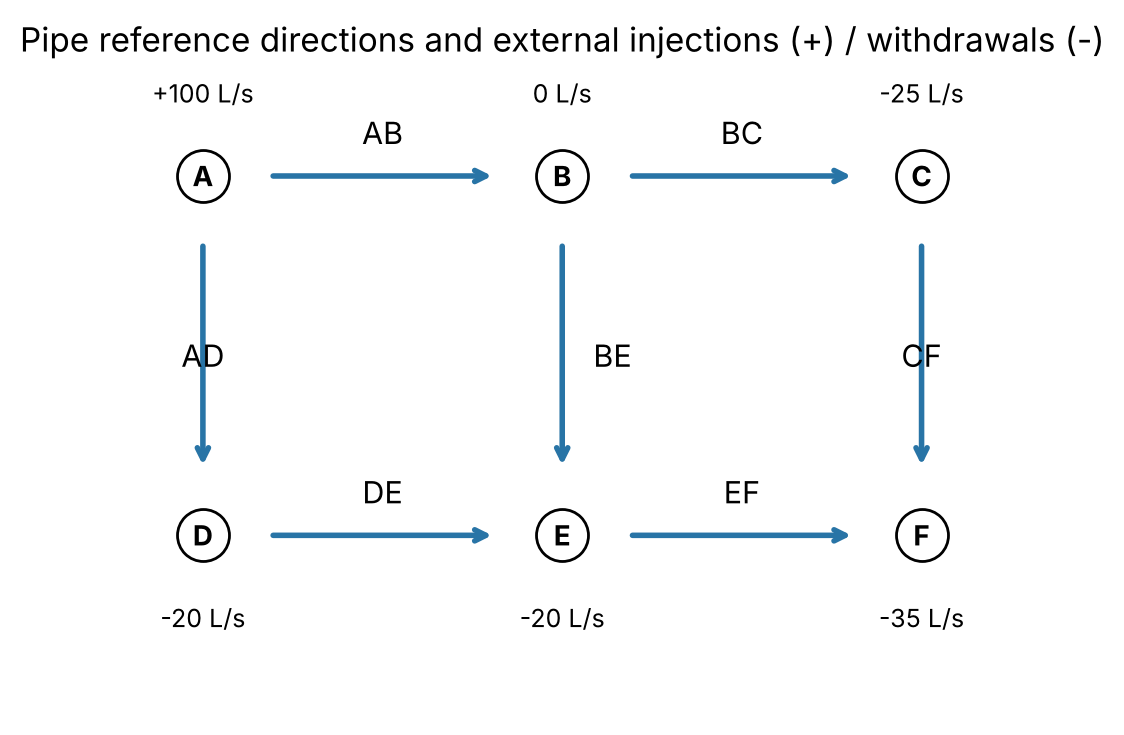

In [2]:
# Open a wide figure that leaves room for node and pipe annotations.
fig, ax = plt.subplots(figsize=(8, 4.2))
# Draw each pipe by visiting its stored tail and head in the same array order.
for index, (tail, head) in enumerate(pipe_ends):
    # Look up the diagram coordinates of the pipe's named tail.
    x0, y0 = node_positions[tail]
    # Look up the diagram coordinates of the pipe's named head.
    x1, y1 = node_positions[head]
    # Draw a directional arrow shortened at each end so it misses node circles.
    ax.annotate('', xy=(x0 + 0.82 * (x1 - x0), y0 + 0.82 * (y1 - y0)), xytext=(x0 + 0.18 * (x1 - x0), y0 + 0.18 * (y1 - y0)), arrowprops={'arrowstyle': '->', 'lw': 2, 'color': '#2874A6'})
    # Put the shared pipe label to its right and the other pipe labels nearby.
    offset_x = 0.14 if pipe_names[index] == 'BE' else 0.0
    # Offset horizontal labels upward and other vertical labels to the left.
    offset_y = 0.12 if y0 == y1 else 0.0
    # Identify the pipe next to its direction arrow.
    ax.text((x0 + x1) / 2 + offset_x, (y0 + y1) / 2 + offset_y, pipe_names[index], ha='center', va='center', fontsize=11)
# Visit every junction to display its given external supply or demand.
for node, (x, y) in node_positions.items():
    # Make the junction prominent without obscuring the arrows.
    ax.scatter(x, y, s=350, color='white', edgecolor='black', zorder=3)
    # Label the node at the middle of its circle.
    ax.text(x, y, node, ha='center', va='center', zorder=4, fontweight='bold')
    # Find the positive injection or negative withdrawal for this node.
    injection = external_flow[node_names.index(node)]
    # Place top-row injections above nodes and bottom-row withdrawals below nodes.
    label_y = y + 0.23 if y == 1 else y - 0.23
    # Show a through-junction as zero rather than a misleading positive zero.
    demand_label = '0' if injection == 0 else f'{injection:+.0f}'
    # Explain the signed external value without covering a vertical pipe arrow.
    ax.text(x, label_y, f'{demand_label} L/s', ha='center', va='center', fontsize=9)
# Give the drawing enough margin for its demand labels.
ax.set(xlim=(-0.35, 2.35), ylim=(-0.50, 1.30), title='Pipe reference directions and external injections (+) / withdrawals (-)')
# Make the two squares visually square without implying physical pipe length.
ax.set_aspect('equal', adjustable='box')
# Hide unused drawing axes so only the network remains.
ax.axis('off')
# Display the network topology as the basis for every later calculation.
plt.show()

## 2. Continuity at every junction

Define the **node–pipe incidence matrix** $B$ as $+1$ at the pipe's named tail, $-1$ at its named head, and zero elsewhere. If $Q$ is the vector of signed flows and $b$ is positive for supply and negative for withdrawal, continuity is

$$BQ=b.$$

For example, at B: pipe AB enters, while BC and BE leave. Thus $-Q_{AB}+Q_{BC}+Q_{BE}=0$, initially $-70+30+40=0$ L/s. At C: $-Q_{BC}+Q_{CF}=-25$ L/s, the negative withdrawal. The starting flows deliberately satisfy **every** junction balance, although their loop head balances will be wrong. A correction around a complete loop must keep $BQ=b$ exactly in algebra (up to floating-point rounding in Python).

In [3]:
# Initialize a six-row by seven-column node–pipe incidence matrix with zeros.
incidence = np.zeros((len(node_names), len(pipe_names)))
# Fill one column for every directed pipe in the stored ordering.
for pipe_index, (tail, head) in enumerate(pipe_ends):
    # Count reference-direction flow as leaving its tail.
    incidence[node_names.index(tail), pipe_index] = 1.0
    # Count the same reference-direction flow as entering its head.
    incidence[node_names.index(head), pipe_index] = -1.0
# Calculate the net outward pipe flow at every node for the initial guess.
initial_node_balance = incidence @ initial_flow
# Display the required injection and the actual initial balance side by side.
for node, required, actual in zip(node_names, external_flow, initial_node_balance):
    # Print a row in L/s so a student can hand-check the six equations.
    print(f'{node}: required b={required:+6.1f}, initial BQ={actual:+6.1f} L/s')
# Check every junction independently of the later energy equations.
assert np.allclose(initial_node_balance, external_flow, atol=1e-12)

A: required b=+100.0, initial BQ=+100.0 L/s
B: required b=  +0.0, initial BQ=  +0.0 L/s
C: required b= -25.0, initial BQ= -25.0 L/s
D: required b= -20.0, initial BQ= -20.0 L/s
E: required b= -20.0, initial BQ= -20.0 L/s
F: required b= -35.0, initial BQ= -35.0 L/s


## 3. From a flow to a signed head change

At fixed positive $r$, $h(Q)=rQ|Q|$ is continuous through $Q=0$ and changes sign if the physical flow reverses. In our network $r$ is supplied directly in m/(L/s)$^2$; it already incorporates a simplified pipe-loss model. For a fixed Darcy friction factor $f$ and **SI flow in m³/s**, Darcy–Weisbach gives

$$h=\frac{8fL}{\pi^2gD^5}\,Q|Q|,\qquad r_{\mathrm{L/s}}=\frac{8fL}{\pi^2gD^5}\times10^{-6}.$$

The factor $10^{-6}$ appears because one L/s equals $10^{-3}$ m³/s **and flow is squared**. We will use one illustrative $L$, $D$, and constant $f$ only to check the coefficient's scale. The seven resistances remain the specified teaching inputs; we have not inferred seven real pipe geometries. The fixed-$f$ formula is not a general claim that turbulent friction factor is constant under all operating conditions.

In [4]:
# Define a signed head-change function for a scalar flow and positive resistance.
def head_change(flow, resistance):
    # State that the return value is a signed head change in metres.
    """Return r*Q*abs(Q), with Q in L/s and r in m/(L/s)^2."""
    # Reject non-finite flow and physically invalid resistance values.
    if not np.isfinite(flow) or not np.isfinite(resistance) or resistance <= 0.0:
        # Explain which parameter domain makes the model meaningful.
        raise ValueError('require finite flow and finite positive resistance')
    # Preserve the sign of flow while making its head-change magnitude quadratic.
    return resistance * flow * abs(flow)

# Evaluate one positive example with the supplied AB pipe resistance.
positive_drop = head_change(10.0, resistances[0])
# Evaluate the same physical magnitude with a reversed flow direction.
negative_drop = head_change(-10.0, resistances[0])
# Verify that a reference flow of zero gives zero signed pipe head change.
zero_drop = head_change(0.0, resistances[0])
# Display the three results to teach the role of the absolute value.
print(f'AB model: h(+10)={positive_drop:+.3f} m, h(-10)={negative_drop:+.3f} m, h(0)={zero_drop:+.3f} m')
# Verify odd symmetry explicitly rather than relying on one printed result.
assert np.isclose(negative_drop, -positive_drop) and zero_drop == 0.0
# Choose illustrative SI parameters for a single fixed-friction-factor calculation.
example_length, example_diameter, example_friction, gravity = 1000.0, 0.30, 0.020, 9.81
# Convert the Darcy–Weisbach coefficient to a flow measured in L/s.
example_resistance = 8.0 * example_friction * example_length / (np.pi**2 * gravity * example_diameter**5) * 1e-6
# Print this illustrative scale without equating it to a particular pipe in the network.
print(f'Illustrative fixed-f Darcy coefficient: {example_resistance:.6f} m/(L/s)^2')

AB model: h(+10)=+0.100 m, h(-10)=-0.100 m, h(0)=+0.000 m
Illustrative fixed-f Darcy coefficient: 0.000680 m/(L/s)^2


## 4. Loop directions and residuals

Choose a traversal direction for each square. It need not match the physical flow. Write $s_{i\ell}=+1$ if loop $\ell$ traverses pipe $i$ in its named reference direction, $-1$ if it traverses it in reverse, and $0$ if it does not visit the pipe.

| Pipe | Named direction | Left loop A–B–E–D–A | Right loop B–C–F–E–B |
|:--|:--|--:|--:|
| AB | A → B | +1 | 0 |
| BC | B → C | 0 | +1 |
| DE | D → E | −1 | 0 |
| EF | E → F | 0 | −1 |
| AD | A → D | −1 | 0 |
| BE | B → E | +1 | −1 |
| CF | C → F | 0 | +1 |

Let the columns of $C$ hold these signs. The signed head residual for loop $\ell$ is $F_\ell=\sum_i s_{i\ell}h_i(Q_i)$, or $F=C^\mathsf{T}h(Q)$. Both residuals must approach zero metres. A loop correction changes flows by $Q\leftarrow Q+C_{:,\ell}\Delta_\ell$. Because every loop returns to its starting node, $BC=0$ and continuity is preserved. Notice that **BE receives opposite signs in the two corrections**.

In [5]:
# Store each loop as a full vector of pipe-direction signs in the shared pipe order.
cycle = np.array([[1.0, 0.0], [0.0, 1.0], [-1.0, 0.0], [0.0, -1.0], [-1.0, 0.0], [1.0, -1.0], [0.0, 1.0]])
# Define readable labels for the two independent loop traversals.
loop_names = ['A-B-E-D-A', 'B-C-F-E-B']
# Check that both signed circulation vectors leave all six node balances untouched.
assert np.allclose(incidence @ cycle, 0.0, atol=1e-12)
# Compute one signed head change for each pipe in the initial guess.
initial_heads = np.array([head_change(q, r) for q, r in zip(initial_flow, resistances)])
# Sum signed pipe head changes around each oriented loop.
initial_loop_residuals = cycle.T @ initial_heads
# Print the two nonzero residuals that the method must remove.
for name, residual in zip(loop_names, initial_loop_residuals):
    # Preserve the sign to show which way the initial loop correction will point.
    print(f'Initial loop {name}: F={residual:+.4f} m')
# Show the shared pipe's opposite signs directly from the two cycle columns.
assert cycle[pipe_names.index('BE'), 0] == -cycle[pipe_names.index('BE'), 1]

Initial loop A-B-E-D-A: F=+4.6800 m
Initial loop B-C-F-E-B: F=-1.2675 m


## 5. Derive one Hardy Cross flow correction

The derivative of the signed law is $h_i'(Q_i)=2r_i|Q_i|$ (including derivative zero at $Q_i=0$). If we add the **same signed loop circulation** $s_{i\ell}\Delta_\ell$ to each pipe, a first-order approximation to the new loop residual is

$$F_\ell(Q+C_{:,\ell}\Delta_\ell)\approx F_\ell(Q)+\Delta_\ell\sum_i s_{i\ell}^2\,2r_i|Q_i|.$$

Setting this approximation to zero gives

$$\boxed{\Delta_\ell=-\frac{\sum_i s_{i\ell}r_iQ_i|Q_i|}{\sum_i s_{i\ell}^2\,2r_i|Q_i|}}.$$

The numerator is in **metres**; the denominator is in **metres per (L/s)**, so $\Delta$ is in **L/s**. For the left loop's initial $F=+4.68$ m, the correction should be **negative**, reducing its positive oriented circulation. The equation is a local linearization, so a first correction will generally leave a nonzero residual. Recompute after updating. In a network with shared pipes, apply the second loop's correction to the **latest** flows, including the changed BE value.

In [6]:
# Select the left loop's sign column for one transparent first correction.
left_signs = cycle[:, 0]
# Identify each nonzero signed contribution to the left-loop sum.
print('Pipe    Q (L/s)    s       h (m)    s*h (m)   2r|Q| (m/(L/s))')
# Visit every pipe in the stored order so the hand calculation can be traced.
for index, sign in enumerate(left_signs):
    # Exclude the three pipes that the left loop does not traverse.
    if sign != 0.0:
        # Calculate the derivative of this pipe's signed head law.
        local_derivative = 2.0 * resistances[index] * abs(initial_flow[index])
        # Print the head contribution and denominator contribution before summing.
        print(f'{pipe_names[index]:>4} {initial_flow[index]:10.3f} {sign:+4.0f} {initial_heads[index]:11.4f} {sign*initial_heads[index]:11.4f} {local_derivative:15.4f}')
# Sum the positive derivative weights for pipes in the left loop.
left_derivative = np.sum(left_signs**2 * 2.0 * resistances * np.abs(initial_flow))
# Divide the negative initial head residual by that derivative.
left_correction = -initial_loop_residuals[0] / left_derivative
# Update all seven pipe flows with zero on pipes outside the left loop.
after_left = initial_flow + left_signs * left_correction
# Measure the left residual after applying the linearized correction.
left_remaining = (cycle.T @ (resistances * after_left * np.abs(after_left)))[0]
# Show that the first correction changed flow but did not perfectly solve the nonlinear equation.
print(f'Left: F0={initial_loop_residuals[0]:+.4f} m; derivative={left_derivative:.4f} m/(L/s)')
# Show the sign, units, and resulting nonzero residual clearly.
print(f'First correction={left_correction:+.6f} L/s; remaining left F={left_remaining:+.6f} m')
# Display the left-loop pipe updates, including the shared BE pipe.
for name, before, after, sign in zip(pipe_names, initial_flow, after_left, left_signs):
    # Omit pipes not visited by the current loop to keep the table focused.
    if sign != 0.0:
        # Show old and new values so a student can reproduce the arithmetic.
        print(f'{name}: s={sign:+.0f}, {before:8.3f} -> {after:8.3f} L/s')
# Verify that adding the circulation did not change any junction injection.
assert np.allclose(incidence @ after_left, external_flow, atol=1e-12)
# Check that the residual magnitude decreased for this starting example.
assert abs(left_remaining) < abs(initial_loop_residuals[0])

Pipe    Q (L/s)    s       h (m)    s*h (m)   2r|Q| (m/(L/s))
  AB     70.000   +1      4.9000      4.9000          0.1400
  DE     10.000   -1      0.2000     -0.2000          0.0400
  AD     30.000   -1      1.6200     -1.6200          0.1080
  BE     40.000   +1      1.6000      1.6000          0.0800
Left: F0=+4.6800 m; derivative=0.3680 m/(L/s)
First correction=-12.717391 L/s; remaining left F=-0.291118 m
AB: s=+1,   70.000 ->   57.283 L/s
DE: s=-1,   10.000 ->   22.717 L/s
AD: s=-1,   30.000 ->   42.717 L/s
BE: s=+1,   40.000 ->   27.283 L/s


## 6. Implement sequential corrections for both loops

A **sweep** visits left, then right. For each loop we calculate the residual and derivative from the *current* flow array, then immediately update that array. The code records the maximum correction in L/s and the maximum loop residual in metres after each full sweep. Both must meet their separately labelled tolerances. We also impose a maximum number of sweeps and detect a zero derivative, so failure cannot silently become an infinite loop or a division by zero.

This is the classical successive loop-correction scheme. A simultaneous two-variable Newton step appears in an **optional** later section for comparison. A small correction alone can be misleading if the residual remains large, so the stopping rule tests both. `max_sweeps` guards termination; it is not a claim that the method always converges for arbitrary inputs.

In [7]:
# Define a reusable solver that keeps the caller's initial array unchanged.
def hardy_cross(start, resistance, cycles, flow_tolerance=1e-9, head_tolerance=1e-9, max_sweeps=100):
    # Explain the returned pipe flows and per-sweep diagnostic records.
    """Apply sequential signed loop corrections and return (flows, history)."""
    # Convert flow and resistance inputs to independent floating-point arrays.
    flows = np.array(start, dtype=float, copy=True)
    # Convert resistance values without changing their supplied ordering.
    coefficients = np.asarray(resistance, dtype=float)
    # Convert loop columns to a numeric array for consistent indexing.
    loops = np.asarray(cycles, dtype=float)
    # Check dimensions before indexing any pipe or loop.
    if flows.ndim != 1 or coefficients.shape != flows.shape or loops.ndim != 2 or loops.shape[0] != len(flows) or loops.shape[1] < 1:
        # Report incompatible inputs instead of producing an obscure matrix error.
        raise ValueError('pipe arrays and cycle rows must agree; provide at least one loop')
    # Reject invalid coefficients, starting flows, or loop entries.
    if not np.all(np.isfinite(flows)) or not np.all(np.isfinite(coefficients)) or not np.all(coefficients > 0.0) or not np.all(np.isfinite(loops)):
        # State the required finite and positive input domains.
        raise ValueError('flows and cycle entries must be finite; resistances positive')
    # Validate both physically distinct tolerance scales and the work cap.
    if not np.isfinite(flow_tolerance) or flow_tolerance <= 0.0 or not np.isfinite(head_tolerance) or head_tolerance <= 0.0 or isinstance(max_sweeps, bool) or not isinstance(max_sweeps, int) or max_sweeps < 1:
        # Make the stopping and bounded-work contract explicit.
        raise ValueError('require positive tolerances and a positive integer max_sweeps')
    # Check that no selected loop column is identically zero.
    if np.any(np.sum(loops**2, axis=0) == 0.0):
        # An empty loop would have a zero denominator for every correction.
        raise ValueError('each cycle column must contain at least one pipe')
    # Keep (sweep number, maximum correction, maximum residual) records.
    history = []
    # Limit work even if a difficult input does not converge.
    for sweep in range(1, max_sweeps + 1):
        # Reset the largest flow adjustment for this full pass.
        largest_correction = 0.0
        # Visit columns one at a time, using freshly updated flows each time.
        for loop_index in range(loops.shape[1]):
            # Select the signs for the current loop, including zero for absent pipes.
            signs = loops[:, loop_index]
            # Calculate the current signed head residual in metres.
            residual = np.sum(signs * coefficients * flows * np.abs(flows))
            # Calculate the positive local derivative in m/(L/s).
            derivative = np.sum(signs**2 * 2.0 * coefficients * np.abs(flows))
            # Detect an all-zero-flow loop before performing a division.
            if derivative == 0.0:
                # Ask for a nondegenerate continuity-satisfying starting guess.
                raise ValueError('zero loop derivative; choose a different initial flow')
            # Linearize the current loop equation to obtain a signed correction.
            correction = -residual / derivative
            # Immediately update even the pipes shared with later loops.
            flows += signs * correction
            # Remember the largest absolute correction during this sweep.
            largest_correction = max(largest_correction, abs(correction))
        # Recompute both loop residuals from the full updated flow vector.
        all_residuals = loops.T @ (coefficients * flows * np.abs(flows))
        # Record the worst absolute residual in metres, across all loops.
        largest_residual = float(np.max(np.abs(all_residuals)))
        # Save one diagnostic triple for the iteration history and graph.
        history.append((sweep, largest_correction, largest_residual))
        # Stop only when both a flow and a head criterion have been satisfied.
        if largest_correction < flow_tolerance and largest_residual < head_tolerance:
            # Return a distinct result array and all diagnostic records.
            return flows, history
    # Report lack of convergence instead of silently returning an unbalanced answer.
    raise RuntimeError('Hardy Cross did not meet both tolerances within max_sweeps')

In [8]:
# Solve the network from the original continuity-satisfying initial guess.
solution_flow, history = hardy_cross(initial_flow, resistances, cycle)
# Display each full sweep's worst correction and head residual with units.
for sweep, maximum_change, maximum_head in history:
    # Use scientific notation so the convergence trend remains visible.
    print(f'Sweep {sweep:2d}: max |delta Q|={maximum_change:.3e} L/s, max |F|={maximum_head:.3e} m')
# Show the final flow corresponding to each stored pipe direction.
for name, flow in zip(pipe_names, solution_flow):
    # A negative number would mean physical flow opposite to the named direction.
    print(f'{name}: Q={flow:+.6f} L/s')
# Confirm the original input vector was not changed by the solver.
assert np.array_equal(initial_flow, [70.0, 30.0, 10.0, 30.0, 30.0, 40.0, 5.0])

Sweep  1: max |delta Q|=1.272e+01 L/s, max |F|=3.812e-01 m
Sweep  2: max |delta Q|=9.290e-01 L/s, max |F|=1.069e-02 m
Sweep  3: max |delta Q|=2.629e-02 L/s, max |F|=2.817e-04 m
Sweep  4: max |delta Q|=6.929e-04 L/s, max |F|=7.683e-06 m
Sweep  5: max |delta Q|=1.890e-05 L/s, max |F|=2.098e-07 m
Sweep  6: max |delta Q|=5.160e-07 L/s, max |F|=5.729e-09 m
Sweep  7: max |delta Q|=1.409e-08 L/s, max |F|=1.564e-10 m
Sweep  8: max |delta Q|=3.847e-10 L/s, max |F|=4.272e-12 m
AB: Q=+58.238614 L/s
BC: Q=+31.883278 L/s
DE: Q=+21.761386 L/s
EF: Q=+28.116722 L/s
AD: Q=+41.761386 L/s
BE: Q=+26.355336 L/s
CF: Q=+6.883278 L/s


## 7. Validate both laws and reconstruct junction heads

The two checks are independent constraints: $BQ=b$ tests conservation of water at every junction, whereas $C^\mathsf{T}h(Q)=0$ tests the energy balance around each loop. We also perform a useful **path-independence check**. Assign an illustrative total head of 100 m at A, then propagate the head along a spanning set of pipes AB, BC, AD, BE, and CF using $H_{\rm tail}-H_{\rm head}=h_i$. The remaining DE and EF pipes give **independent predictions** for E and F. Agreement verifies that the signed head changes are mutually consistent.

The chosen 100 m is a reference boundary value. Flow distribution here depends on the specified injections and resistances, not on adding the same constant to every head. Total hydraulic head is not automatically gauge pressure: pressure at a real location would need elevation, velocity-head conventions, and an appropriate boundary condition.

In [9]:
# Calculate net outward pipe flow at each junction after the iteration.
final_node_balance = incidence @ solution_flow
# Calculate all seven signed pipe head changes from the final flows.
final_head_changes = resistances * solution_flow * np.abs(solution_flow)
# Sum final signed head changes around both independent loops.
final_loop_balance = cycle.T @ final_head_changes
# Report the largest continuity error in L/s.
print(f'Max node continuity error: {np.max(np.abs(final_node_balance - external_flow)):.3e} L/s')
# Report the largest energy residual in metres.
print(f'Max loop head residual: {np.max(np.abs(final_loop_balance)):.3e} m')
# Set one illustrative total-head boundary value at the source junction.
head_A = 100.0
# Propagate from A to B along pipe AB, following its named direction.
head_B = head_A - final_head_changes[0]
# Propagate from B to C along pipe BC.
head_C = head_B - final_head_changes[1]
# Propagate from A to D along pipe AD.
head_D = head_A - final_head_changes[4]
# Propagate from B to E along the shared pipe BE.
head_E = head_B - final_head_changes[5]
# Propagate from C to F along pipe CF.
head_F = head_C - final_head_changes[6]
# Store the six total-head values for a readable node table.
node_heads = dict(zip(node_names, [head_A, head_B, head_C, head_D, head_E, head_F]))
# Display head values without calling them local pressure values.
for node, total_head in node_heads.items():
    # Print a node-head row with metres of hydraulic head.
    print(f'Node {node}: total head={total_head:.6f} m')
# Predict E along the independent D-to-E pipe rather than the selected B-to-E path.
head_E_via_D = head_D - final_head_changes[2]
# Predict F along the independent E-to-F pipe rather than the selected C-to-F path.
head_F_via_E = head_E - final_head_changes[3]
# Display the two route-consistency differences in metres.
print(f'E route difference={head_E_via_D - head_E:+.3e} m; F route difference={head_F_via_E - head_F:+.3e} m')
# Check every junction at a tight but realistic floating-point tolerance.
assert np.allclose(final_node_balance, external_flow, atol=1e-10)
# Check both loop equations separately from the solver's internal stop test.
assert np.max(np.abs(final_loop_balance)) < 1e-9
# Check the two unused pipe relationships against propagated node heads.
assert np.isclose(head_E_via_D, head_E, atol=1e-9) and np.isclose(head_F_via_E, head_F, atol=1e-9)

Max node continuity error: 1.421e-14 L/s
Max loop head residual: 4.272e-12 m
Node A: total head=100.000000 m
Node B: total head=96.608264 m
Node C: total head=95.083449 m
Node D: total head=96.860776 m
Node E: total head=95.913660 m
Node F: total head=94.965000 m
E route difference=-4.277e-12 m; F route difference=+0.000e+00 m


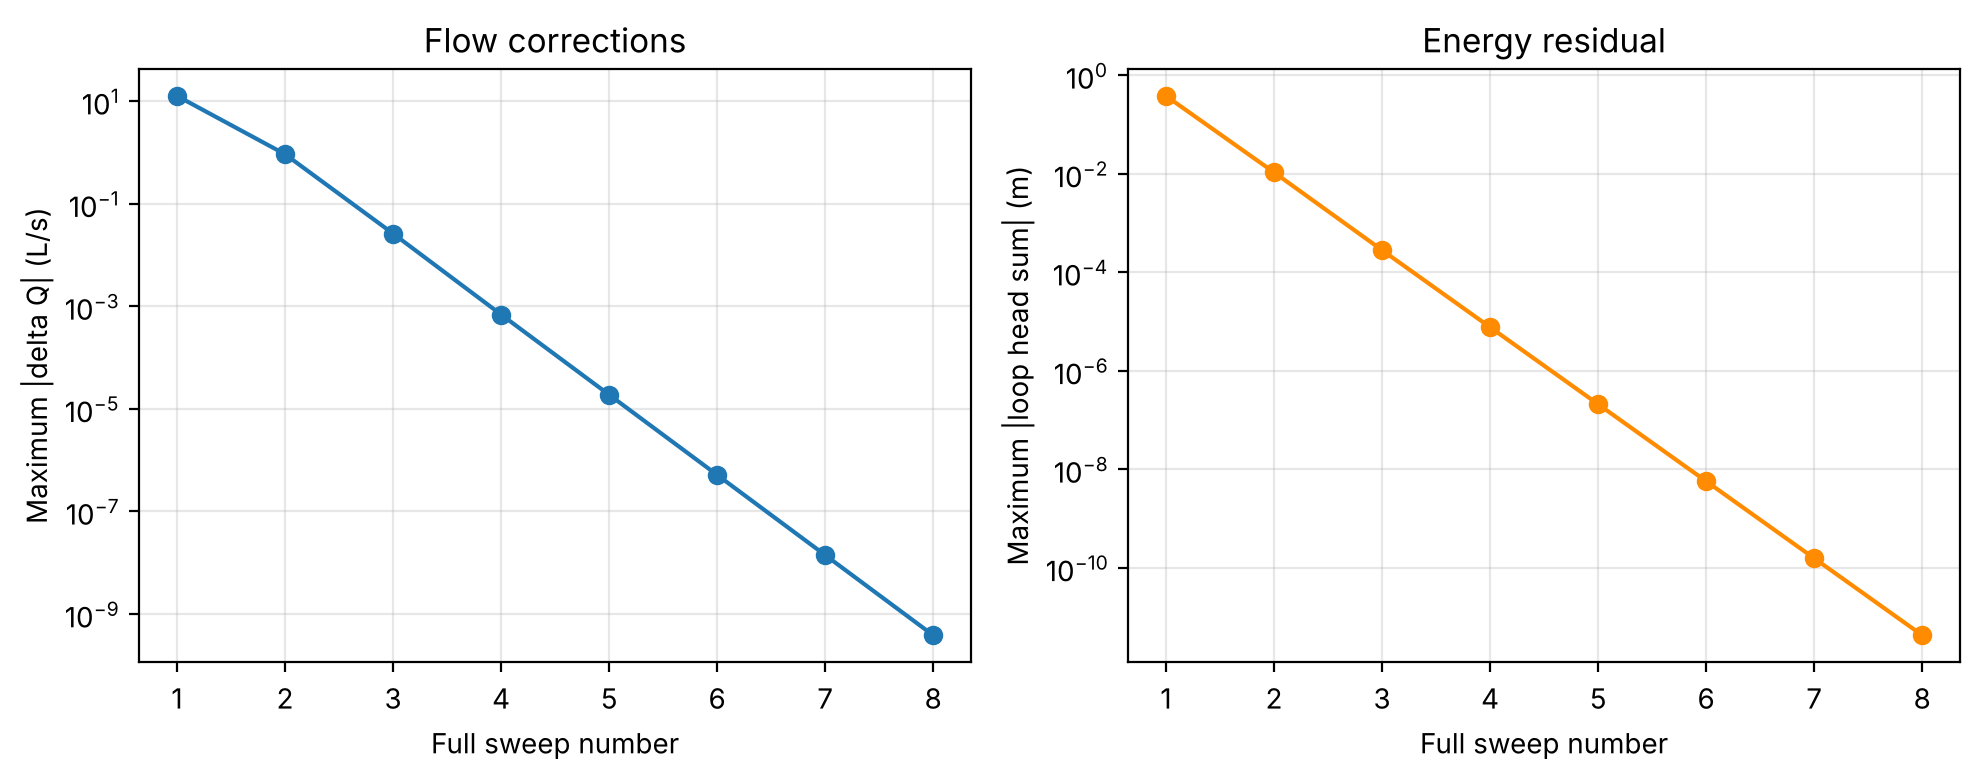

In [10]:
# Extract sweep numbers for a clear horizontal convergence axis.
sweep_numbers = [record[0] for record in history]
# Extract flow corrections in L/s for their own labelled vertical axis.
flow_diagnostics = [record[1] for record in history]
# Extract loop head residuals in metres for a separate plot.
head_diagnostics = [record[2] for record in history]
# Create side-by-side figures because the two residuals have different units.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
# Plot flow correction magnitude on logarithmic scale over successive sweeps.
axes[0].semilogy(sweep_numbers, flow_diagnostics, marker='o')
# Label the count and the flow diagnostic, including its unit.
axes[0].set(xlabel='Full sweep number', ylabel='Maximum |delta Q| (L/s)', title='Flow corrections')
# Plot both-loop energy imbalance after each completed sweep.
axes[1].semilogy(sweep_numbers, head_diagnostics, marker='o', color='darkorange')
# Label the head residual separately to avoid treating it as a flow error.
axes[1].set(xlabel='Full sweep number', ylabel='Maximum |loop head sum| (m)', title='Energy residual')
# Add reference lines to both plots without changing the numerical results.
for ax in axes:
    # Light grids make the logarithmic trend easier to read.
    ax.grid(True, which='both', alpha=0.3)
# Prevent axis titles from colliding inside the notebook page.
fig.tight_layout()
# Display convergence of both stopping criteria.
plt.show()

**Checkpoint.** The initial junction errors are zero and remain close to machine precision; the loop head residuals shrink with sweeps. The two loop residuals are checked **after both corrections**, because the second correction changes shared pipe BE and can disturb the first loop again. The pressure-head cross-check uses different routes through the solved graph. These checks establish consistency for this specified model, not accuracy of the assumed pipe resistances in a physical system.

## 8. Draw the solved flows and compare with the initial guess

All seven final signed flows happen to be positive, so the physical flow agrees with every chosen reference arrow in this example. In another valid case a pipe may have negative flow. The bar graph separates the original feasible guess from the balanced answer; satisfying continuity by itself is not enough to determine the looped network.

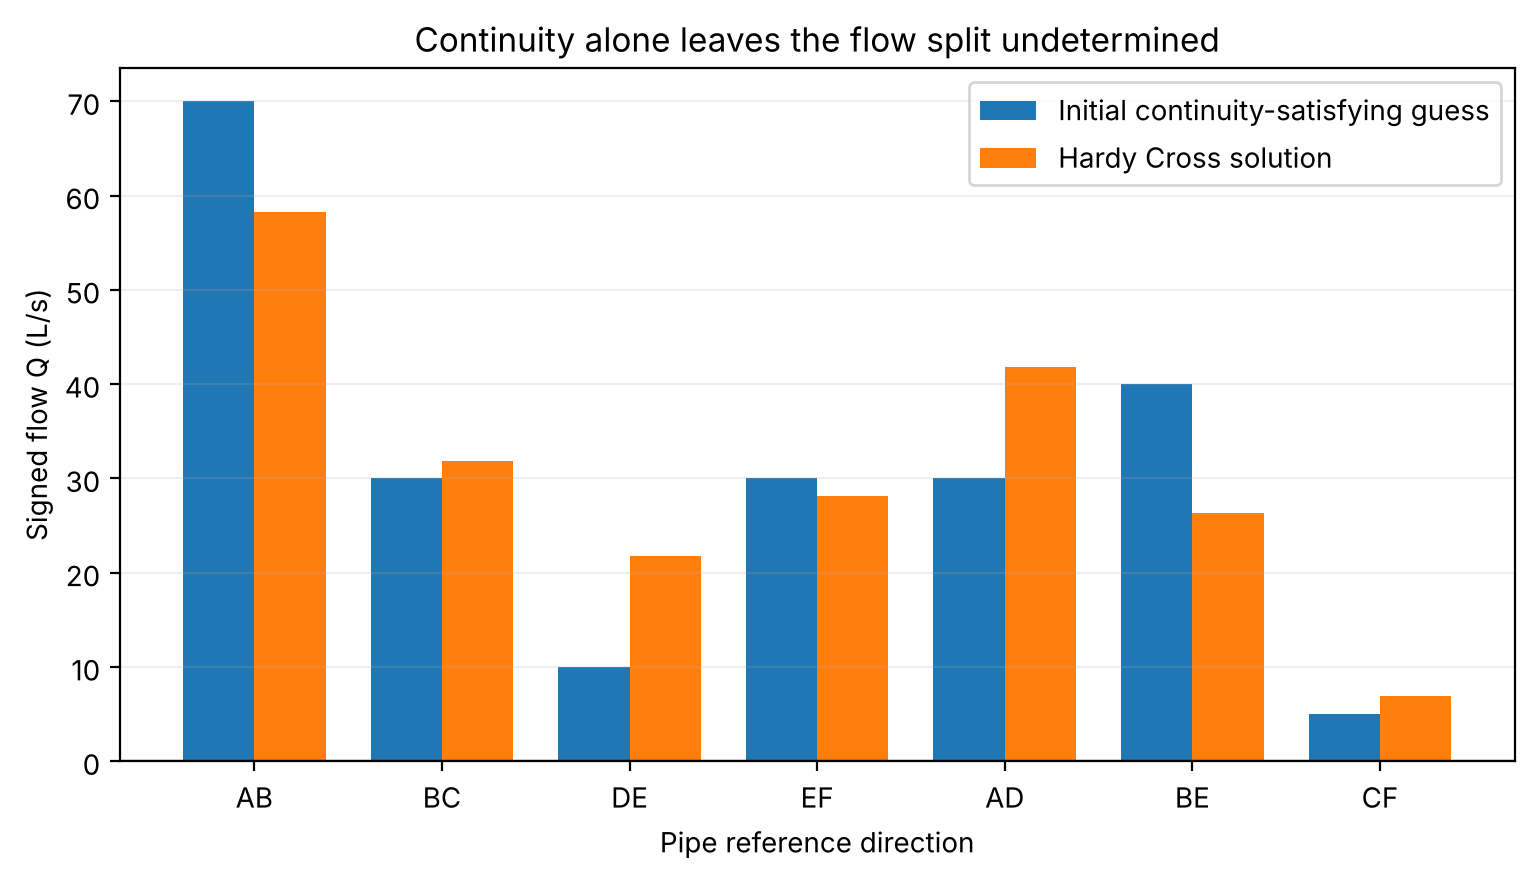

In [11]:
# Allocate horizontal positions for the seven pipe labels.
bar_positions = np.arange(len(pipe_names))
# Create side-by-side bars for the feasible initial guess and final solution.
fig, ax = plt.subplots(figsize=(9, 4.5))
# Plot initial signed flows using the common L/s scale.
ax.bar(bar_positions - 0.19, initial_flow, width=0.38, label='Initial continuity-satisfying guess')
# Plot balanced signed flows in a second color at the same pipe positions.
ax.bar(bar_positions + 0.19, solution_flow, width=0.38, label='Hardy Cross solution')
# Mark zero explicitly in case another example has reverse-direction flow.
ax.axhline(0.0, color='black', linewidth=0.8)
# Show short pipe names at their exact array indices.
ax.set_xticks(bar_positions, pipe_names)
# Give the flow axis and figure a precise meaning.
ax.set(ylabel='Signed flow Q (L/s)', xlabel='Pipe reference direction', title='Continuity alone leaves the flow split undetermined')
# Identify which bars belong to the initial and final arrays.
ax.legend()
# Add a faint guide for approximate magnitude readings.
ax.grid(axis='y', alpha=0.2)
# Display the network-wide change from the initial guess.
plt.show()

## 9. Test a different valid starting guess

A useful programming test is to start from a very different set of flows that still satisfies continuity. If we add any combination of the two loop columns to the original guess, $B(Q_0+Cz)=b$ because $BC=0$. Choose $z=(20,-10)$ L/s, which makes DE and CF **negative**. The signed $Q|Q|$ law and derivative $2r|Q|$ must still work. For this example both starts should converge to the same result, but that observation does not prove convergence or uniqueness for every possible network.

In [12]:
# Choose two initial circulation changes in L/s, one for each loop.
start_circulation = np.array([20.0, -10.0])
# Generate a distinct but continuity-satisfying initial pipe flow vector.
alternate_start = initial_flow + cycle @ start_circulation
# Print all seven flows, including any negative reference-direction values.
for name, value in zip(pipe_names, alternate_start):
    # Make flow reversal explicit to reinforce sign handling.
    print(f'Alternate start {name}: {value:+.1f} L/s')
# Verify the second guess obeys all six external supply and demand constraints.
assert np.allclose(incidence @ alternate_start, external_flow, atol=1e-12)
# Run exactly the same solver without changing the pipe resistances or loops.
alternate_solution, alternate_history = hardy_cross(alternate_start, resistances, cycle)
# Measure the largest difference between two independently iterated solutions.
start_difference = np.max(np.abs(alternate_solution - solution_flow))
# Report convergence work and numerical agreement in L/s.
print(f'Alternate start: {len(alternate_history)} sweeps; max solution difference={start_difference:.3e} L/s')
# Check agreement at a scale far smaller than the displayed flow precision.
assert start_difference < 1e-7

Alternate start AB: +90.0 L/s
Alternate start BC: +20.0 L/s
Alternate start DE: -10.0 L/s
Alternate start EF: +40.0 L/s
Alternate start AD: +10.0 L/s
Alternate start BE: +70.0 L/s
Alternate start CF: -5.0 L/s
Alternate start: 9 sweeps; max solution difference=9.564e-12 L/s


### A diagnostic trap: loop balance cannot repair an invalid starting guess

The iteration function assumes the caller supplied a continuity-satisfying start. Suppose we add 1 L/s to AB alone. The starting guess now has an extra 1 L/s leaving A and arriving at B, with no corresponding change in external supply or demand. Every later cycle correction still has $BC=0$, so **no amount of loop balancing can remove this original node error**. The next cell intentionally demonstrates that mistake and reports the failed junction test. It does not promote the resulting flows as a solution to the specified network.

In [13]:
# Make an independent copy so the known-good initial example is preserved.
invalid_start = initial_flow.copy()
# Add one L/s to AB alone, which violates the fixed external injections.
invalid_start[pipe_names.index('AB')] += 1.0
# Compute the continuity error that a loop-only update will preserve.
invalid_initial_error = incidence @ invalid_start - external_flow
# Let the loop solver balance heads for this deliberately wrong start.
invalid_loop_solution, invalid_history = hardy_cross(invalid_start, resistances, cycle)
# Compute the node residuals after all loop energy residuals have converged.
invalid_final_error = incidence @ invalid_loop_solution - external_flow
# Confirm that the original node error remains despite the loop corrections.
print(f'Node errors before: {invalid_initial_error} L/s')
# Show the unchanged node errors after solving the wrong problem.
print(f'Node errors after:  {invalid_final_error} L/s')
# Check the diagnostic rather than treating its numerical result as valid.
assert np.allclose(invalid_final_error, invalid_initial_error, atol=1e-12)
# Verify that the example truly remains inconsistent with the stated demands.
assert np.max(np.abs(invalid_final_error)) > 0.5

Node errors before: [ 1. -1.  0.  0.  0.  0.] L/s
Node errors after:  [ 1.00000000e+00 -1.00000000e+00  7.10542736e-15  0.00000000e+00
  0.00000000e+00 -7.10542736e-15] L/s


## 10. What happens if one pipe becomes more resistant?

A bottleneck study connects the algorithm with design intuition. Double the coefficient of the **shared BE pipe only**, retaining all external injections and withdrawals. Re-solve the network from the original feasible guess, check both laws again, and see which routes gain or lose flow. This is a scenario within our fixed-coefficient model; it is not a prediction for a specific valve or a pipe of unprovided geometry.

In [14]:
# Copy the original coefficients so the baseline calculation remains unchanged.
bottleneck_resistances = resistances.copy()
# Identify the shared pipe by name instead of relying on an unexplained index.
shared_index = pipe_names.index('BE')
# Double only that pipe's quadratic head-change coefficient.
bottleneck_resistances[shared_index] *= 2.0
# Resolve the new scenario with the same external supply and demand vector.
bottleneck_flow, bottleneck_history = hardy_cross(initial_flow, bottleneck_resistances, cycle)
# Calculate its node continuity error independently of the solver.
bottleneck_node_error = incidence @ bottleneck_flow - external_flow
# Calculate its two loop residuals with the altered coefficients.
bottleneck_loop_error = cycle.T @ (bottleneck_resistances * bottleneck_flow * np.abs(bottleneck_flow))
# Print the baseline, altered flow, and change for every pipe.
for name, baseline, changed in zip(pipe_names, solution_flow, bottleneck_flow):
    # Include a signed change so rerouting can be traced pipe by pipe.
    print(f'{name}: baseline={baseline:8.3f}, doubled-BE-r={changed:8.3f}, change={changed-baseline:+8.3f} L/s')
# Test the intended bottleneck result for the shared pipe in this example.
assert bottleneck_flow[shared_index] < solution_flow[shared_index]
# Confirm that water is still conserved at every junction in the changed model.
assert np.max(np.abs(bottleneck_node_error)) < 1e-10
# Confirm that both energy loops meet the specified head-balance accuracy.
assert np.max(np.abs(bottleneck_loop_error)) < 1e-9

AB: baseline=  58.239, doubled-BE-r=  57.138, change=  -1.101 L/s
BC: baseline=  31.883, doubled-BE-r=  33.819, change=  +1.936 L/s
DE: baseline=  21.761, doubled-BE-r=  22.862, change=  +1.101 L/s
EF: baseline=  28.117, doubled-BE-r=  26.181, change=  -1.936 L/s
AD: baseline=  41.761, doubled-BE-r=  42.862, change=  +1.101 L/s
BE: baseline=  26.355, doubled-BE-r=  23.319, change=  -3.037 L/s
CF: baseline=   6.883, doubled-BE-r=   8.819, change=  +1.936 L/s


**Interpretation.** The BE flow falls by about 3.04 L/s, while several other flows change to maintain the four withdrawals and two loop balances. A higher resistance in one pipe affects the *whole connected network*. The detailed redistribution depends on all seven resistance coefficients, so the printed before-and-after table is more informative than a slogan about one pipe.

## 11. Optional: a coupled two-loop Newton check

Our sequential Hardy Cross method corrects each loop with a one-variable derivative. A different algorithm can solve for both loop circulations at once. Write $Q=Q_0+Cz$ and $F(z)=C^\mathsf{T}h(Q)$. The $2\times2$ Jacobian is

$$J(z)=C^\mathsf{T}\operatorname{diag}(2r_i|Q_i|)C.$$

Solve $J\,\delta z=-F$ at each iteration. The **off-diagonal terms** capture the shared BE pipe: they are generally nonzero. This provides a cross-check of the sequential implementation using a different update scheme. It solves the *same modeled equations*, so agreement does not independently validate the physical resistance inputs. If a Jacobian is singular, a real solver needs additional safeguards; the bounded example below works with this network.

In [15]:
# Begin the independent two-loop correction vector at the original guess.
newton_circulations = np.zeros(2)
# Cap the number of coupled updates so an unexpected failure terminates.
for step in range(20):
    # Convert current circulation values into all seven pipe flows.
    trial_flows = initial_flow + cycle @ newton_circulations
    # Calculate the two current head residuals as a vector in metres.
    trial_residual = cycle.T @ (resistances * trial_flows * np.abs(trial_flows))
    # Stop when both loop residuals are already below the prescribed head tolerance.
    if np.max(np.abs(trial_residual)) < 1e-10:
        # Leave the bounded loop with the converged circulation parameters.
        break
    # Calculate each pipe's local derivative in m/(L/s).
    pipe_derivatives = 2.0 * resistances * np.abs(trial_flows)
    # Assemble the full two-by-two Jacobian without explicitly creating a diagonal matrix.
    jacobian = cycle.T @ (pipe_derivatives[:, None] * cycle)
    # Solve the coupled linearized equations for both loop changes at once.
    newton_change = np.linalg.solve(jacobian, -trial_residual)
    # Add both changes to the circulation values before the next evaluation.
    newton_circulations += newton_change
# Reject non-convergence rather than printing an unchecked final vector.
else:
    # A twenty-step cap is a programming safeguard, not a convergence theorem.
    raise RuntimeError('coupled Newton check did not converge')
# Compute pipe flows implied by the independent coupled update history.
newton_flow = initial_flow + cycle @ newton_circulations
# Report the number of updates and the shared-pipe cross-term in the final Jacobian.
print(f'Coupled Newton updates: {step}; final loop circulation={newton_circulations} L/s')
# Show the worst disagreement between sequential and coupled algorithms.
print(f'Max disagreement: {np.max(np.abs(newton_flow - solution_flow)):.3e} L/s')
# Recompute the last Jacobian at the final flows so its cross-term is properly labelled.
final_jacobian = cycle.T @ ((2.0 * resistances * np.abs(newton_flow))[:, None] * cycle)
# Identify the nonzero coupling generated by the shared pipe BE.
print(f'Final Jacobian off-diagonal: J12={final_jacobian[0,1]:+.6f} m/(L/s)')
# Check the two methods agree to much better than the tabulated precision.
assert np.max(np.abs(newton_flow - solution_flow)) < 1e-7
# Verify that the shared pipe produces a nonzero interaction between loops.
assert abs(final_jacobian[0, 1]) > 0.0

Coupled Newton updates: 4; final loop circulation=[-11.76138607   1.88327754] L/s
Max disagreement: 1.081e-11 L/s
Final Jacobian off-diagonal: J12=-0.052711 m/(L/s)


## 12. Engineering interpretation and limits

- **Continuity and energy serve different roles.** We started with exact junction balances; the algorithm reduced loop head imbalances while preserving them.
- **Direction is a bookkeeping choice.** The name AB means the *positive reference direction* A → B. A negative solved $Q_{AB}$ would mean flow B → A. The signed law $rQ|Q|$ remains valid across reversal.
- **Head and pressure need care.** With no pump inside a pipe, its tail-to-head **total hydraulic head** difference follows the signed loss law. Pressure alone additionally depends on elevation and velocity-head assumptions; the example does not supply a real pressure profile.
- **Fixed resistance is an idealization.** If friction factor depends on Reynolds number, the head law and its derivative must be updated consistently. Pumps, valves, reservoirs with prescribed heads, transient storage, leakage, and demand that changes with pressure require different equations or boundary conditions.
- **A residual is a numerical diagnostic.** A result can satisfy the two modeled balances while remaining inaccurate for a real network because its diameters, roughness, demand, or boundary data are wrong.

### Independent practice

Try the questions before reading the answer cell.

1. At B, write the node balance using the three connected named flows. Why must it remain zero after any loop correction?
2. For $Q=-20$ L/s and $r=0.002$ m/(L/s)$^2$, calculate signed $h(Q)$ and $h'(Q)$ with their units.
3. The initial left-loop residual is positive. What sign should its first correction have? Which way does the shared BE flow change?
4. Explain why the right-loop correction should use the *updated* BE value. Why do we evaluate both residuals again after a complete sweep?
5. Inspect the baseline and bottleneck table. Which pipe was altered, and how much did its solved flow change? Why were junction withdrawals unchanged?
6. Change `start_circulation` to `[-20.0, 10.0]` and run its cell again. Confirm continuity and compare the final flows.
7. Optional: change the single head coefficient in `bottleneck_resistances` to 1.5 times its baseline value. Re-solve and compare with the doubling case. Make a graph if helpful.
8. Optional: identify which element of $J=C^\mathsf{T}\operatorname{diag}(2r|Q|)C$ represents coupling between loops and which pipe causes it.

In [16]:
# Compute the signed head change in the worked reversal example.
practice_head = head_change(-20.0, 0.002)
# Evaluate its positive local derivative using the magnitude of flow.
practice_derivative = 2.0 * 0.002 * abs(-20.0)
# Calculate the shared pipe change observed in the bottleneck experiment.
practice_shared_change = bottleneck_flow[shared_index] - solution_flow[shared_index]
# Report the numerical values with the physically appropriate units.
print(f'Q2: signed head change={practice_head:+.3f} m; derivative={practice_derivative:.3f} m/(L/s)')
# Report the direction and size of the shared-pipe response.
print(f'Q5: change in BE flow={practice_shared_change:+.3f} L/s')
# Verify the sign and magnitude by separate elementary arithmetic.
assert np.isclose(practice_head, -0.8) and np.isclose(practice_derivative, 0.08)

Q2: signed head change=-0.800 m; derivative=0.080 m/(L/s)
Q5: change in BE flow=-3.037 L/s


**Answer notes.** (1) At B: $-Q_{AB}+Q_{BC}+Q_{BE}=0$ L/s. Since every loop returns to its start, its signed update contributes zero net flow at each node. (2) The head change is $-0.8$ m and derivative $+0.08$ m/(L/s). (3) The first left correction is negative; BE decreases because its left sign is $+1$. (4) Both loops share BE, so later calculations must use the changed value, and correcting the right loop can disturb the left residual. (5) Only the BE resistance was doubled; its flow decreases about 3.04 L/s. The fixed external demands and loop circulations keep node balance unchanged. (6) A different feasible start should converge to the same example result; the experiment alone does not guarantee all starts converge. (7) Treat any observed trend as a scenario for this model. (8) $J_{12}=J_{21}$ is the coupling term; only BE appears in both loop columns.

### Further reading

- Hardy Cross, [*Analysis of Flow in Networks of Conduits or Conductors*](https://www.ideals.illinois.edu/items/4876), University of Illinois Engineering Experiment Station Bulletin 286 (1936). The original method.
- Course handout, *Hardy Cross Method*, pp. 1–8. A worked teaching introduction to flow and loop-head balances; its pipe example is separate from our constructed network.
- Wikipedia, [*Hardy Cross method*](https://en.wikipedia.org/wiki/Hardy_Cross_method) and [*Pipe network analysis*](https://en.wikipedia.org/wiki/Pipe_network_analysis). Introductory context and terminology; consult Cross's original work and a hydraulics text for authoritative derivations and engineering design.

**Conclusion.** The Python implementation makes a hand calculation traceable: initial flows meet continuity, loop updates reduce the two energy residuals, and node and head-route checks test the result. Changing one coefficient demonstrates how a local bottleneck redistributes flow throughout a coupled network. The method illustrates both iterative programming and the need to keep engineering assumptions, sign conventions, units, and numerical checks visible.